# Практика 2.2. Сверточная нейронная сеть (CNN)

**Задача:** классификация рукописных японских символов хираганы в старинном начертании **кудзуси-дзи** (10 классов).

**Датасет:** [Kuzushiji-MNIST (KMNIST)](https://github.com/rois-codh/kmnist) — 70 000 изображений 28×28 в оттенках серого (60 000 train + 10 000 test), подготовлен Центром открытых данных в гуманитарных науках (CODH, Япония) по оцифрованным книгам эпохи Эдо. По формату совпадает с MNIST, но заметно сложнее: один и тот же символ в старинной рукописи может выглядеть совершенно по-разному.

| Класс | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|---|
| Символ | お | き | す | つ | な | は | ま | や | れ | を |
| Чтение | o | ki | su | tsu | na | ha | ma | ya | re | wo |

**Почему CNN:** у изображения есть пространственная структура — соседние пиксели связаны. Свёрточный слой применяет к картинке небольшие обучаемые фильтры (3×3), которые находят локальные признаки (штрихи, изгибы) в любом месте изображения, используя одни и те же веса.

## 0. Зависимости и импорты

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlflow "tensorflow>=2.16"

In [2]:
import hashlib
import os
from pathlib import Path
from urllib.request import urlretrieve

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import keras
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from keras import layers
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

## 1. Настройки и вспомогательные функции

In [3]:
EXPERIMENT_NAME = "p2_cnn_kmnist"
BASE_URL = "http://codh.rois.ac.jp/kmnist/dataset/kmnist/"
FILES = {
    "train_images": "kmnist-train-imgs.npz",
    "train_labels": "kmnist-train-labels.npz",
    "test_images": "kmnist-test-imgs.npz",
    "test_labels": "kmnist-test-labels.npz",
}
CLASS_NAMES = ["o", "ki", "su", "tsu", "na", "ha", "ma", "ya", "re", "wo"]
IMG_SIZE = 28
MIN_INK_FRACTION = 0.01
BATCH_SIZE = 128
MAX_EPOCHS = 30
LEARNING_RATE = 1e-3


SEED = 42
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
MLFLOW_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"

keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
print(f"Keras {keras.__version__}, backend: {keras.backend.backend()}")


def download(url, filename):
    path = DATA_DIR / filename
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def quality_report(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_%": (frame.isna().mean() * 100).round(2),
        "unique": frame.nunique(),
    })


def iqr_outlier_mask(frame, k=1.5):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return (frame < q1 - k * iqr) | (frame > q3 + k * iqr)


class MlflowLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        mlflow.log_metrics({k: float(v) for k, v in (logs or {}).items()}, step=epoch)


def plot_history(history, metric):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, key in zip(axes, ["loss", metric]):
        ax.plot(history.history[key], label="train")
        ax.plot(history.history[f"val_{key}"], label="validation")
        ax.set(title=key, xlabel="эпоха")
        ax.legend()
    plt.tight_layout()
    return fig


def load_npz(key):
    return np.load(download(BASE_URL + FILES[key], FILES[key]))["arr_0"]


def image_hashes(images):
    return np.array([hashlib.md5(img.tobytes()).hexdigest() for img in images])


def show_grid(images, titles, n_cols=10, size=1.3):
    n_rows = int(np.ceil(len(images) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * size, n_rows * size * 1.15))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, img, title in zip(np.ravel(axes), images, titles):
        ax.imshow(img.squeeze(), cmap="gray_r")
        ax.set_title(title, fontsize=8)
    plt.tight_layout()
    return fig

2026/11/11 12:43:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/11 12:43:21 INFO mlflow.store.db.utils: Updating database tables
2026/11/11 12:43:24 INFO mlflow.tracking.fluent: Experiment with name 'p2_cnn_kmnist' does not exist. Creating a new experiment.


Keras 3.13.2, backend: tensorflow


**Трекинг экспериментов.** Метрики каждой эпохи пишутся в MLflow через callback `MlflowLogger` (база `mlflow.db` в корне репозитория). Просмотр: `mlflow ui --backend-store-uri sqlite:///mlflow.db` из корня репозитория → http://127.0.0.1:5000.

## 2. Загрузка данных
Файлы `.npz` (≈ 20 МБ) скачиваются один раз в `data/`.

In [4]:
train_images, train_labels = load_npz("train_images"), load_npz("train_labels")
test_images, test_labels = load_npz("test_images"), load_npz("test_labels")
print(f"train: {train_images.shape} {train_images.dtype}, test: {test_images.shape}")
print(f"Диапазон пикселей: [{train_images.min()}, {train_images.max()}], метки: {np.unique(train_labels)}")

train: (60000, 28, 28) uint8, test: (10000, 28, 28)
Диапазон пикселей: [0, 255], метки: [0 1 2 3 4 5 6 7 8 9]


## 3. Качество данных
Для изображений «битые данные» выглядят иначе, чем для таблиц. Проверяем:
1. **Формат:** размер 28×28, тип `uint8`, значения 0–255, метки 0–9, число картинок = числу меток.
2. **Пустые/вырожденные изображения:** без «чернил» или почти пустые (доля ненулевых пикселей < 1 %), а также однотонные.
3. **Дубликаты** внутри train (по MD5-хэшу пикселей), в том числе с **противоречивыми метками**.
4. **Утечка:** одинаковые изображения в train и test — завысили бы оценку качества.

In [5]:
for name, images, labels in [("train", train_images, train_labels), ("test", test_images, test_labels)]:
    assert images.shape[1:] == (IMG_SIZE, IMG_SIZE), f"{name}: неверный размер"
    assert len(images) == len(labels), f"{name}: число картинок и меток не совпадает"
    print(f"{name}: изображений без метки (пропусков): {len(images) - len(labels)}")
    ink = (images > 0).mean(axis=(1, 2))
    print(f"{name}: метки вне 0–9: {(~np.isin(labels, range(10))).sum()}, "
          f"пустых: {(images.max(axis=(1, 2)) == 0).sum()}, "
          f"почти пустых (<{MIN_INK_FRACTION:.0%}): {(ink < MIN_INK_FRACTION).sum()}, "
          f"однотонных: {(images.min(axis=(1, 2)) == images.max(axis=(1, 2))).sum()}")

train: изображений без метки (пропусков): 0
train: метки вне 0–9: 0, пустых: 0, почти пустых (<1%): 0, однотонных: 0
test: изображений без метки (пропусков): 0
test: метки вне 0–9: 0, пустых: 0, почти пустых (<1%): 0, однотонных: 0


In [6]:
train_hashes = image_hashes(train_images)
test_hashes = image_hashes(test_images)

hash_frame = pd.DataFrame({"hash": train_hashes, "label": train_labels})
dup_mask = hash_frame.duplicated("hash", keep="first")
conflict_hashes = hash_frame.groupby("hash")["label"].nunique().loc[lambda s: s > 1].index
conflict_mask = hash_frame["hash"].isin(conflict_hashes)
leak_mask = np.isin(train_hashes, test_hashes)

print(f"Дубликатов внутри train: {dup_mask.sum()}")
print(f"Изображений с противоречивыми метками: {conflict_mask.sum()}")
print(f"Изображений train, совпадающих с test (утечка): {leak_mask.sum()}")

Дубликатов внутри train: 0
Изображений с противоречивыми метками: 0
Изображений train, совпадающих с test (утечка): 0


**Стратегия очистки:** из train удаляем повторные копии дубликатов, все изображения с противоречивыми метками, пересечения с test и пустые картинки. Тестовую выборку не трогаем (кроме пустых изображений), чтобы оценка оставалась сопоставимой с опубликованными результатами.

In [7]:
train_ink = (train_images > 0).mean(axis=(1, 2))
test_ink = (test_images > 0).mean(axis=(1, 2))
keep_train = ~(dup_mask.to_numpy() | conflict_mask.to_numpy() | leak_mask | (train_ink < MIN_INK_FRACTION))
keep_test = test_ink >= MIN_INK_FRACTION

train_images, train_labels, train_ink = train_images[keep_train], train_labels[keep_train], train_ink[keep_train]
test_images, test_labels = test_images[keep_test], test_labels[keep_test]
print(f"После очистки: train {len(train_images)}, test {len(test_images)}")

После очистки: train 60000, test 10000


### Аномалии: «количество чернил»
Доля закрашенных пикселей — простой признак, по которому видно необычные изображения. Посмотрим на самые «бледные» и самые «тёмные» экземпляры по IQR.

Выбросов по доле чернил (IQR): 434 (0.72%)


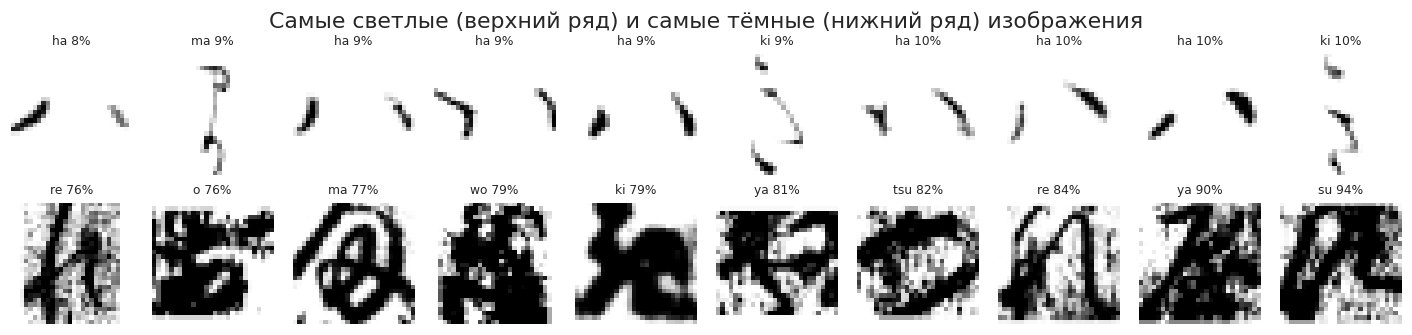

In [8]:
ink_series = pd.Series(train_ink)
ink_outliers = iqr_outlier_mask(ink_series.to_frame())[0].to_numpy()
print(f"Выбросов по доле чернил (IQR): {ink_outliers.sum()} ({ink_outliers.mean():.2%})")

order = np.argsort(train_ink)
extremes = np.concatenate([order[:10], order[-10:]])
show_grid(train_images[extremes], [f"{CLASS_NAMES[train_labels[i]]} {train_ink[i]:.0%}" for i in extremes])
plt.suptitle("Самые светлые (верхний ряд) и самые тёмные (нижний ряд) изображения", y=1.03)
plt.show()

Крайние изображения — это реальные варианты написания (тонкое перо, жирная кисть, частично обрезанный символ), а не ошибки. Удалять их не будем: модель должна уметь работать и с ними. Помогает и аугментация (см. ниже).

## 4. Разведочный анализ (EDA)

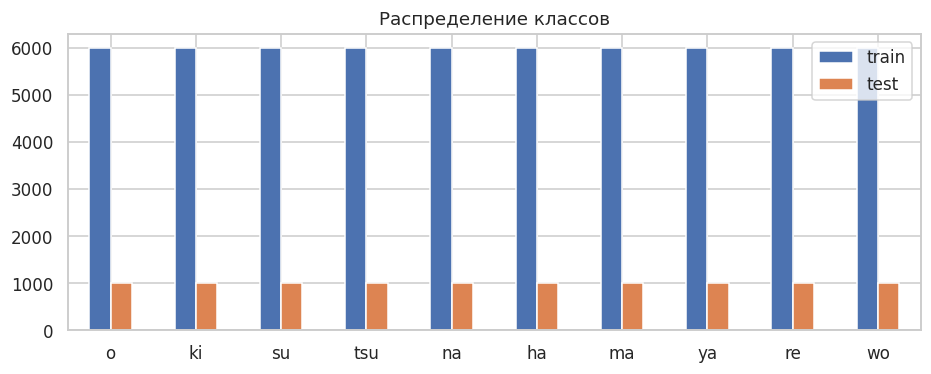

In [9]:
counts = pd.DataFrame({
    "train": pd.Series(train_labels).value_counts().sort_index(),
    "test": pd.Series(test_labels).value_counts().sort_index(),
})
counts.index = CLASS_NAMES
counts.plot.bar(figsize=(10, 3.5), rot=0, title="Распределение классов")
plt.show()

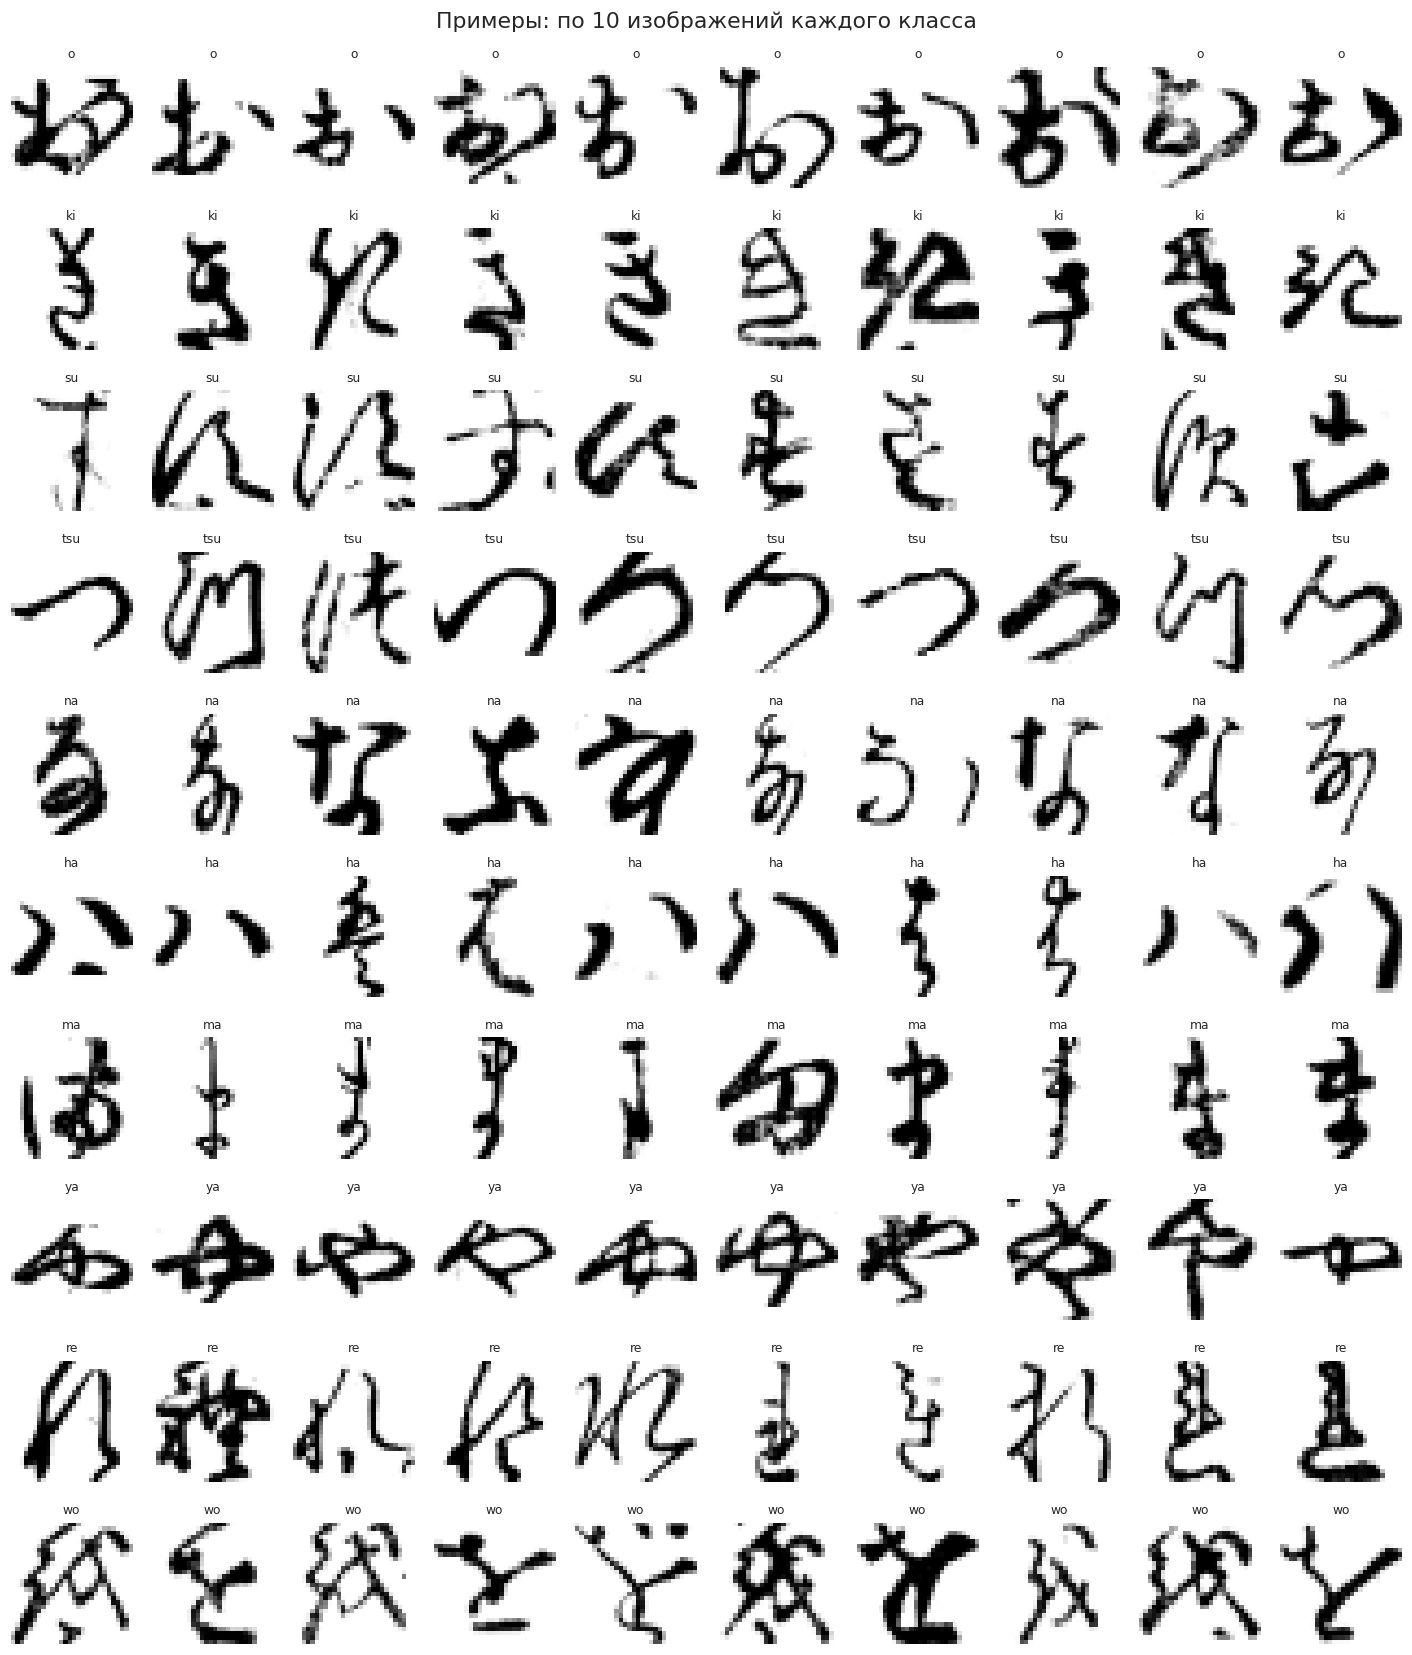

In [10]:
samples = np.concatenate([np.flatnonzero(train_labels == c)[:10] for c in range(10)])
show_grid(train_images[samples], [CLASS_NAMES[train_labels[i]] for i in samples])
plt.suptitle("Примеры: по 10 изображений каждого класса", y=1.01)
plt.show()

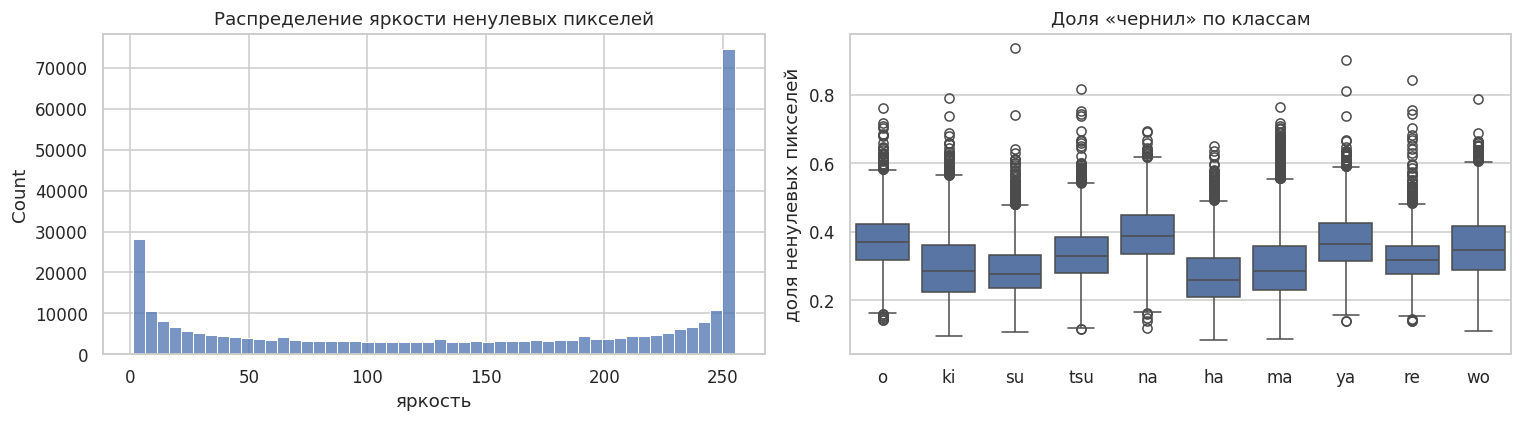

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train_images[train_images > 0].ravel()[::50], bins=50, ax=axes[0])
axes[0].set(title="Распределение яркости ненулевых пикселей", xlabel="яркость")
sns.boxplot(x=pd.Categorical([CLASS_NAMES[l] for l in train_labels], CLASS_NAMES), y=train_ink, ax=axes[1])
axes[1].set(title="Доля «чернил» по классам", ylabel="доля ненулевых пикселей")
plt.tight_layout()
plt.show()

### Средние изображения и матрица корреляции классов
Усредняем все изображения класса и считаем корреляцию Пирсона между «средними символами». Высокая корреляция означает, что классы похожи по форме и модель будет их чаще путать.

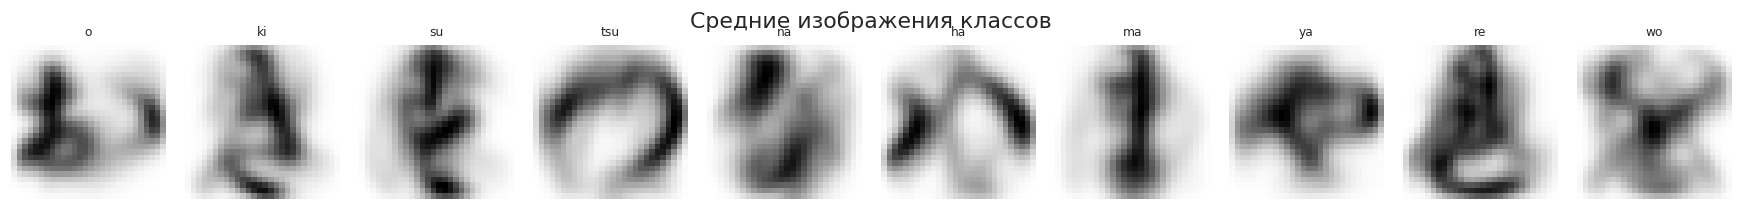

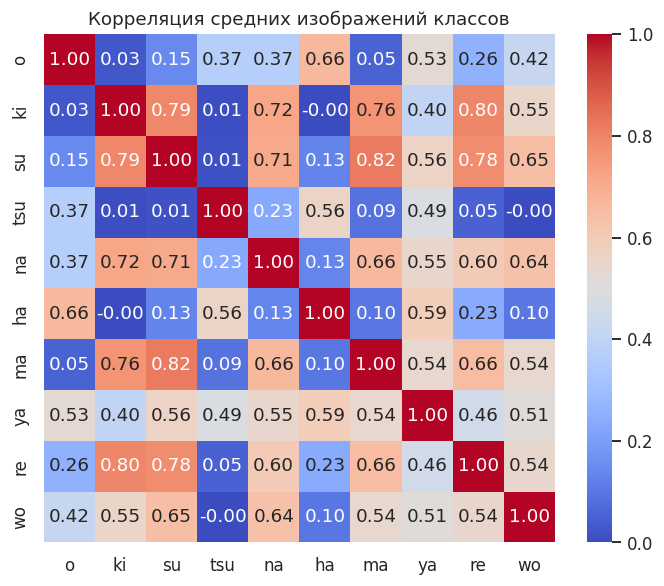

In [12]:
mean_images = np.stack([train_images[train_labels == c].mean(axis=0) for c in range(10)])
show_grid(mean_images, CLASS_NAMES, size=1.6)
plt.suptitle("Средние изображения классов", y=1.05)
plt.show()

class_corr = np.corrcoef(mean_images.reshape(10, -1))
plt.figure(figsize=(7.5, 6))
sns.heatmap(class_corr, annot=True, fmt=".2f", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Корреляция средних изображений классов")
plt.show()

**Наблюдения EDA:**
- все 10 классов в train и test представлены поровну (по 6 000 и 1 000 изображений) — дисбаланса нет;
- яркость пикселей почти бинарная: основная масса — фон (0) и насыщенные «чернила» (≈ 255), промежуточные значения — сглаженные края штрихов;
- доля «чернил» различается по классам: у `na`, `o`, `ya` штрихи «тяжелее» (медиана ≈ 0,37–0,39), у `ha`, `su`, `ki` — «легче» (≈ 0,26–0,29); в каждом классе много выбросов — это разные кисти и почерки;
- средние изображения сильнее всего похожи у пар `su`–`ma` (0,82), `ki`–`re` (0,80), `ki`–`su` (0,79), а `tsu` почти не похож на остальные (корреляция ≤ 0,56).

## 5. Подготовка данных
- **Кодирование:** текстовых значений в датасете нет — метки уже закодированы целыми числами 0–9 (названия символов хранятся отдельно в `CLASS_NAMES`), поэтому дополнительное кодирование не нужно; используем `sparse_categorical_crossentropy`.
- Нормализация яркости в диапазон [0, 1] (`/255`) и добавление канала: `(N, 28, 28)` → `(N, 28, 28, 1)`.
- Из train выделяем 15 % на валидацию (стратифицированно); официальный test используем только в конце.

In [13]:
X = (train_images.astype("float32") / 255.0)[..., np.newaxis]
X_test = (test_images.astype("float32") / 255.0)[..., np.newaxis]
y_test = test_labels.astype("int64")
X_train, X_val, y_train, y_val = train_test_split(
    X, train_labels.astype("int64"), test_size=0.15, stratify=train_labels, random_state=SEED
)
print(f"train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")

train: (51000, 28, 28, 1), val: (9000, 28, 28, 1), test: (10000, 28, 28, 1)


## 6. Архитектура
```
Input 28×28×1
 → аугментация (сдвиг ±8 %, поворот ±5 %, масштаб ±10 %) — только при обучении
 → [Conv 3×3, 32] → BN → [Conv 3×3, 32] → BN → MaxPool 2×2 → Dropout     # 14×14×32
 → [Conv 3×3, 64] → BN → [Conv 3×3, 64] → BN → MaxPool 2×2 → Dropout     # 7×7×64
 → Flatten → Dense 128 → Dropout → Dense 10 (softmax)
```
- **Conv2D** — свёртка: фильтр 3×3 скользит по изображению и выделяет локальный признак; первые слои ловят штрихи, следующие — их комбинации;
- **MaxPooling** уменьшает размер карты признаков вдвое, давая устойчивость к небольшим сдвигам;
- **аугментация** создаёт «новые» варианты изображений на лету — эффективная регуляризация для рукописных символов.

In [14]:
def build_cnn(n_classes, dropout_conv=0.25, dropout_dense=0.4):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="image")
    x = layers.RandomTranslation(0.08, 0.08, fill_mode="constant", name="aug_shift")(inputs)
    x = layers.RandomRotation(0.05, fill_mode="constant", name="aug_rotate")(x)
    x = layers.RandomZoom(0.1, fill_mode="constant", name="aug_zoom")(x)
    for block, filters in enumerate([32, 64], start=1):
        for i in (1, 2):
            x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"conv{block}_{i}")(x)
            x = layers.BatchNormalization(name=f"bn{block}_{i}")(x)
        x = layers.MaxPooling2D(name=f"pool{block}")(x)
        x = layers.Dropout(dropout_conv, name=f"dropout{block}")(x)
    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(128, activation="relu", name="dense")(x)
    x = layers.Dropout(dropout_dense, name="dropout_dense")(x)
    outputs = layers.Dense(n_classes, activation="softmax", name="probabilities")(x)
    model = keras.Model(inputs, outputs, name="kmnist_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


model = build_cnn(len(CLASS_NAMES))
model.summary()

Model: "kmnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_shift (RandomTranslation)   │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_rotate (RandomRotation)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_zoom (RandomZoom)           │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_1 (BatchNormalization)      │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_2 (BatchNormalization)      │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_1 (BatchNormalization)      │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_2 (BatchNormalization)      │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,586 (1.79 MB)

 Trainable params: 468,202 (1.79 MB)

 Non-trainable params: 384 (1.50 KB)

## 7. Обучение
На GPU (в Colab: «Среда выполнения → Сменить среду выполнения → T4 GPU») одна эпоха занимает 10–20 секунд, на CPU — около 4 минут. Ранняя остановка обычно срабатывает за 15–25 эпох.

Epoch 1/30
399/399 - 242s - 608ms/step - accuracy: 0.7516 - loss: 0.7724 - val_accuracy: 0.9159 - val_loss: 0.3230 - learning_rate: 0.0010
Epoch 2/30
399/399 - 259s - 649ms/step - accuracy: 0.8923 - loss: 0.3462 - val_accuracy: 0.9729 - val_loss: 0.0992 - learning_rate: 0.0010
Epoch 3/30
399/399 - 230s - 577ms/step - accuracy: 0.9221 - loss: 0.2555 - val_accuracy: 0.9704 - val_loss: 0.0929 - learning_rate: 0.0010
Epoch 4/30
399/399 - 262s - 657ms/step - accuracy: 0.9350 - loss: 0.2121 - val_accuracy: 0.9803 - val_loss: 0.0705 - learning_rate: 0.0010
Epoch 5/30
399/399 - 233s - 583ms/step - accuracy: 0.9410 - loss: 0.1861 - val_accuracy: 0.9820 - val_loss: 0.0701 - learning_rate: 0.0010
Epoch 6/30
399/399 - 261s - 654ms/step - accuracy: 0.9509 - loss: 0.1609 - val_accuracy: 0.9803 - val_loss: 0.0705 - learning_rate: 0.0010
Epoch 7/30
399/399 - 263s - 659ms/step - accuracy: 0.9523 - loss: 0.1542 - val_accuracy: 0.9828 - val_loss: 0.0603 - learning_rate: 0.0010
Epoch 8/30
399/399 - 233s -

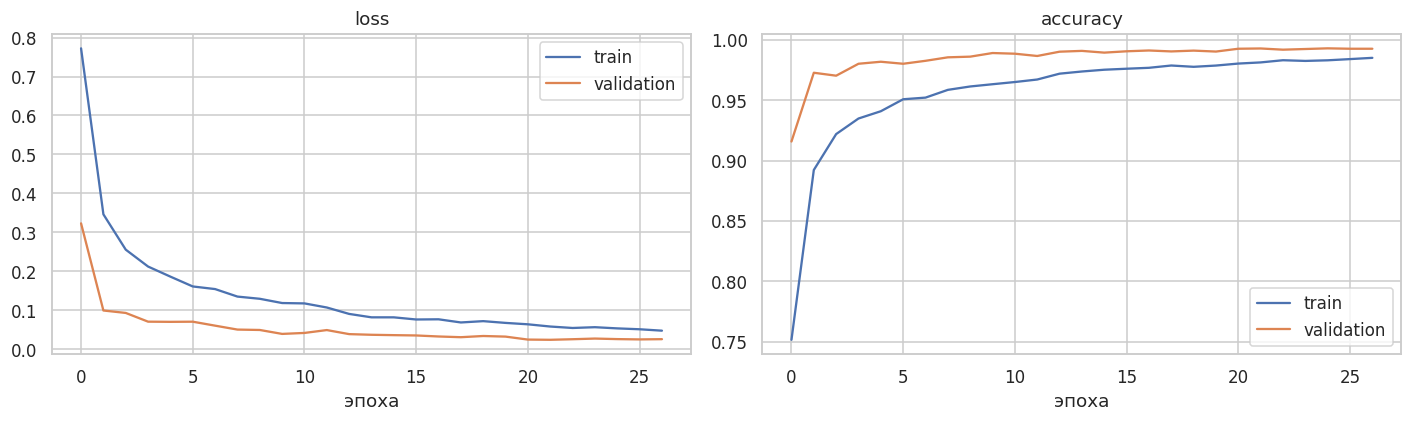

In [15]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    MlflowLogger(),
]
with mlflow.start_run(run_name="kmnist_cnn") as run:
    mlflow.log_params({"lr": LEARNING_RATE, "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS,
                       "n_params": model.count_params(), "augmentation": "shift0.08_rot0.05_zoom0.1"})
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=MAX_EPOCHS,
                        batch_size=BATCH_SIZE, callbacks=callbacks, verbose=2)
run_id = run.info.run_id
history_fig = plot_history(history, "accuracy")
plt.show()

## 8. Оценка на тестовой выборке

In [16]:
test_proba = model.predict(X_test, batch_size=512, verbose=0)
test_pred = test_proba.argmax(axis=1)
test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "f1_macro": f1_score(y_test, test_pred, average="macro"),
}
print(classification_report(y_test, test_pred, target_names=CLASS_NAMES, digits=3))
pd.Series(test_metrics).round(4)

              precision    recall  f1-score   support

           o      0.966     0.980     0.973      1000
          ki      0.980     0.967     0.973      1000
          su      0.976     0.938     0.957      1000
         tsu      0.977     0.990     0.984      1000
          na      0.965     0.953     0.959      1000
          ha      0.989     0.969     0.979      1000
          ma      0.957     0.991     0.973      1000
          ya      0.993     0.979     0.986      1000
          re      0.977     0.992     0.985      1000
          wo      0.975     0.994     0.984      1000

    accuracy                          0.975     10000
   macro avg      0.975     0.975     0.975     10000
weighted avg      0.975     0.975     0.975     10000



,0
accuracy,0.9753
f1_macro,0.9752


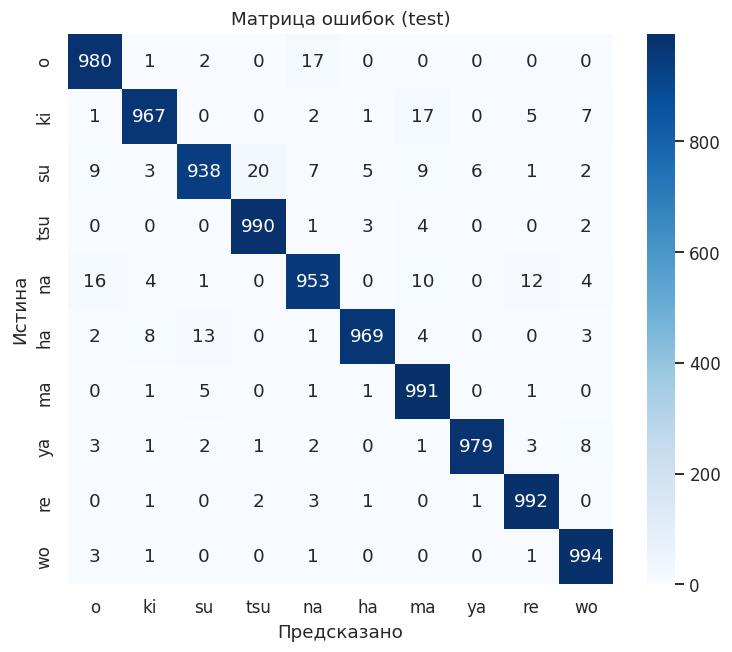

In [17]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(xlabel="Предсказано", ylabel="Истина", title="Матрица ошибок (test)")
plt.show()

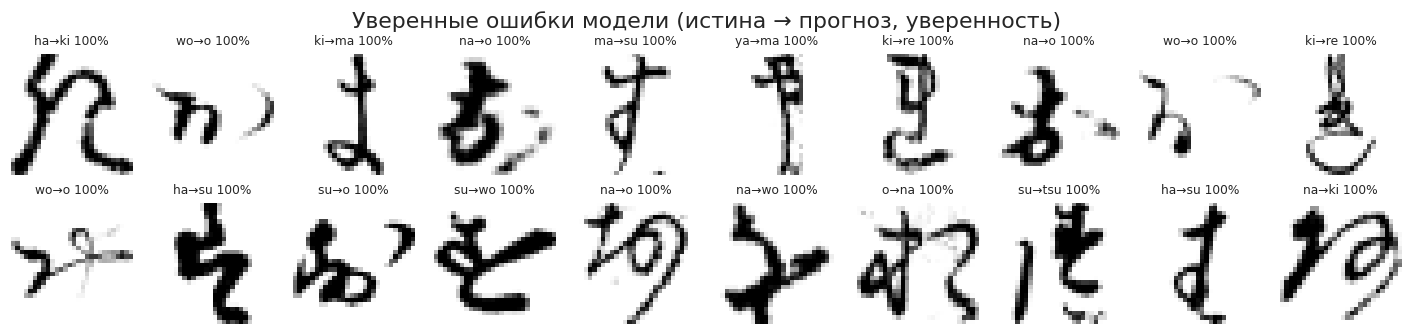

In [18]:
wrong = np.flatnonzero(test_pred != y_test)
worst = wrong[np.argsort(-test_proba[wrong, test_pred[wrong]])][:20]
show_grid(X_test[worst], [f"{CLASS_NAMES[y_test[i]]}→{CLASS_NAMES[test_pred[i]]} {test_proba[i, test_pred[i]]:.0%}" for i in worst])
plt.suptitle("Уверенные ошибки модели (истина → прогноз, уверенность)", y=1.03)
plt.show()

### Что «видит» сверточный слой
Карты признаков первого свёрточного слоя для одного изображения: каждый из 32 фильтров реагирует на свой тип локального рисунка (вертикальные/горизонтальные штрихи, края, изгибы).

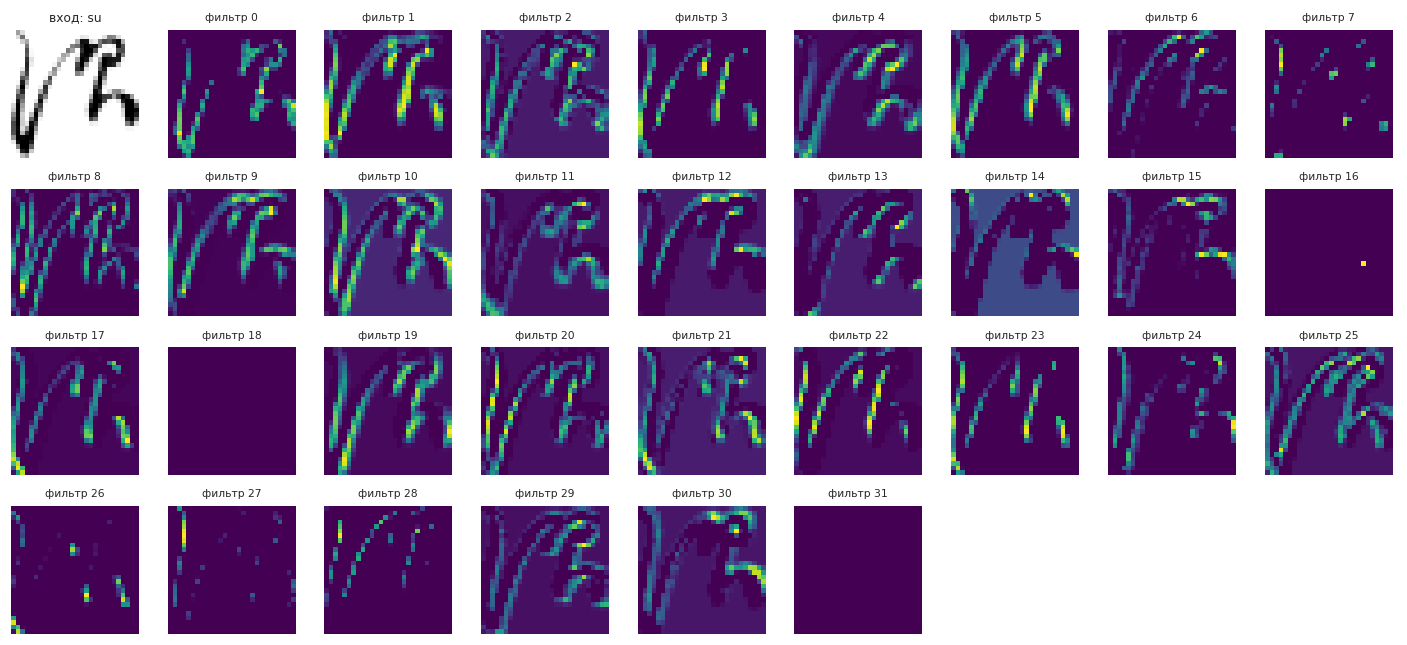

In [19]:
feature_extractor = keras.Model(model.inputs, model.get_layer("conv1_1").output)
feature_maps = feature_extractor.predict(X_test[:1], verbose=0)[0]
fig, axes = plt.subplots(4, 9, figsize=(13, 6))
axes[0, 0].imshow(X_test[0].squeeze(), cmap="gray_r")
axes[0, 0].set_title(f"вход: {CLASS_NAMES[y_test[0]]}", fontsize=8)
for ax, idx in zip(axes.ravel()[1:], range(feature_maps.shape[-1])):
    ax.imshow(feature_maps[..., idx], cmap="viridis")
    ax.set_title(f"фильтр {idx}", fontsize=7)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [20]:
with mlflow.start_run(run_id=run_id):
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_figure(fig, "feature_maps.png")
    mlflow.log_figure(history_fig, "learning_curves.png")
print("Результаты записаны в MLflow")

Результаты записаны в MLflow


## 9. Выводы
- **Качество данных.** Формат всех 70 000 изображений корректен (28×28, `uint8`, значения 0–255, метки 0–9). Пустых, почти пустых и однотонных изображений, пропущенных меток, дубликатов (проверка по MD5-хэшу пикселей), противоречивых меток и пересечений train ↔ test **не найдено** — датасет чистый, код проверки показан полностью. 434 изображения (0,72 %) выбиваются по доле «чернил», но это реальные варианты написания, они оставлены.
- **Подготовка.** Пиксели нормированы в [0, 1], добавлен канал; из train выделено 15 % на валидацию (51 000 / 9 000), официальный test (10 000) использован один раз.
- **Обучение.** CNN из двух свёрточных блоков (≈ 469 тыс. параметров) обучалась 27 эпох; ReduceLROnPlateau четыре раза снизил шаг обучения (с 10⁻³ до 6·10⁻⁵), ранняя остановка вернула веса 22-й эпохи (val_loss 0,024, val accuracy **0,993**). Точность на train (≈ 0,98) ниже, чем на валидации: при обучении работают аугментация и Dropout, которые усложняют задачу, а при проверке отключены — это признак отсутствия переобучения.
- **Итог на тесте:** accuracy **0,975**, F1-macro **0,975**. Лучше всего распознаются `wo`, `re`, `ya`, `tsu` (F1 ≈ 0,985), хуже всего — `su` (0,957) и `na` (0,959).
- **Разрыв валидация → тест** (0,993 → 0,975) — известная особенность KMNIST: тестовые изображения взяты из других книг, с другими почерками. Это хорошо показывает, зачем нужна честная отложенная выборка.
- **Ошибки.** Чаще всего путаются `su` → `tsu` (20 раз), `o` → `na` (17), `ki` → `ma` (17), `na` → `o` (16). Пара `ki`–`ma` похожа и по средним изображениям (0,76), а `su` и `tsu` по средним совсем не похожи (0,01). Значит, путаница возникает из-за отдельных вариантов написания, а не из-за общей формы символа.
- **Карты признаков** первого свёрточного слоя показывают, что фильтры выделяют простые локальные структуры — края и штрихи разных направлений. Следующие слои комбинируют их в части символа; в этом и состоит идея свёрточных сетей.